# Dataset Summary for LLM Context

This notebook works with a battery degradation dataset originally stored in a MATLAB `.mat` file and then converted into a Python pickle file. The data is organized as a nested hierarchy rather than a flat table.

## What the dataset represents
- Each top-level entry is one battery cell experiment.
- The dataset contains 47 cells, keyed as `b1c0` through `b1c46`.
- The data tracks how each battery ages over repeated charge/discharge cycles.
- Some cells are standard life-test batteries, while others are special variable-charge or slow-cycle experiments.

## Top-level structure
Each battery entry in `bat_dict` contains:
- `cycle_life`: the number of cycles until end of life, stored as a number when available, or `NaN` for some special experiments.
- `charge_policy`: a human-readable string describing the charging protocol.
- `summary`: cycle-level summary arrays.
- `cycles`: detailed time-series data for each individual cycle.

## Summary fields
The dataframe in this notebook uses one row per battery and keeps the summary arrays as columns:
- `summary_IR`: internal resistance across cycles.
- `summary_QC`: charge capacity across cycles.
- `summary_QD`: discharge capacity across cycles.
- `summary_Tavg`: average temperature across cycles.
- `summary_Tmin`: minimum temperature across cycles.
- `summary_Tmax`: maximum temperature across cycles.
- `summary_chargetime`: charge time across cycles.
- `summary_cycle`: the cycle index values aligned with the above measurements.

These arrays are useful for degradation trends, feature extraction, and plotting capacity fade or thermal behavior over time.

## Detailed cycle data
Inside `cycles`, each battery contains one entry per cycle. Each cycle stores time-series traces such as:
- `I`: current
- `Qc`: charge capacity trace
- `Qd`: discharge capacity trace
- `Qdlin`: linearized discharge capacity
- `T`: temperature
- `Tdlin`: linearized temperature
- `V`: voltage
- `dQdV`: differential capacity curve
- `t`: time

This nested structure is the right level of detail if you want to study within-cycle behavior, not just per-cycle summaries.

## How to think about the data
- The battery identity is at the top level.
- The cycle progression is stored in the summary arrays.
- The physical trajectory inside a single cycle is stored in the detailed `cycles` traces.
- The dataset is suitable for battery health estimation, remaining useful life prediction, and degradation modeling.

## Important notes
- Some `cycle_life` values are `NaN`; those cells represent special runs and should be handled separately in analysis.
- Some `charge_policy` labels include `-newstructure` or `SLOWCYCLE`, which indicates different experimental protocols.
- The summary arrays are stored as Python lists or numpy arrays after loading; they are not already flattened into tabular scalar columns.

## Suggested LLM prompt context
If you want another LLM to help analyze this dataset, describe it as:
"A battery degradation dataset with 47 cells. Each cell has a charge policy, a cycle life value, cycle-level summary arrays, and detailed per-cycle voltage/current/temperature traces. The goal is to analyze degradation trends, compare charge policies, and build predictive models for cycle life."

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
import pickle

with open('data pkl/batch1.pkl', 'rb') as fp:
    bat_dict = pickle.load(fp)

print(type(bat_dict))
print(bat_dict.keys())

<class 'dict'>
dict_keys(['b1c0', 'b1c1', 'b1c2', 'b1c3', 'b1c4', 'b1c5', 'b1c6', 'b1c7', 'b1c8', 'b1c9', 'b1c10', 'b1c11', 'b1c12', 'b1c13', 'b1c14', 'b1c15', 'b1c16', 'b1c17', 'b1c18', 'b1c19', 'b1c20', 'b1c21', 'b1c22', 'b1c23', 'b1c24', 'b1c25', 'b1c26', 'b1c27', 'b1c28', 'b1c29', 'b1c30', 'b1c31', 'b1c32', 'b1c33', 'b1c34', 'b1c35', 'b1c36', 'b1c37', 'b1c38', 'b1c39', 'b1c40', 'b1c41', 'b1c42', 'b1c43', 'b1c44', 'b1c45', 'b1c46'])


In [3]:
bat_dict['b1c1'].keys()

dict_keys(['cycle_life', 'charge_policy', 'summary', 'cycles'])

In [4]:
keys = list(bat_dict.keys())
for cell_id in keys:
    cell_data = bat_dict[cell_id]
    if np.isnan(cell_data['cycle_life'][0][0]):
        print(f"Cell ID: {cell_id}, Cycle Life: {cell_data['cycle_life'][0][0]}")
        del bat_dict[cell_id]
    

Cell ID: b1c22, Cycle Life: nan
Cell ID: b1c23, Cycle Life: nan
Cell ID: b1c35, Cycle Life: nan
Cell ID: b1c36, Cycle Life: nan
Cell ID: b1c37, Cycle Life: nan
Cell ID: b1c38, Cycle Life: nan
Cell ID: b1c39, Cycle Life: nan
Cell ID: b1c40, Cycle Life: nan


In [11]:
cell_id = 'b1c46'
print(bat_dict[cell_id].keys())
print(bat_dict[cell_id]['summary'].keys())
print(bat_dict[cell_id]['cycles']['1'].keys())

dict_keys(['cycle_life', 'charge_policy', 'summary', 'cycles'])
dict_keys(['IR', 'QC', 'QD', 'Tavg', 'Tmin', 'Tmax', 'chargetime', 'cycle'])
dict_keys(['I', 'Qc', 'Qd', 'Qdlin', 'T', 'Tdlin', 'V', 'dQdV', 't'])


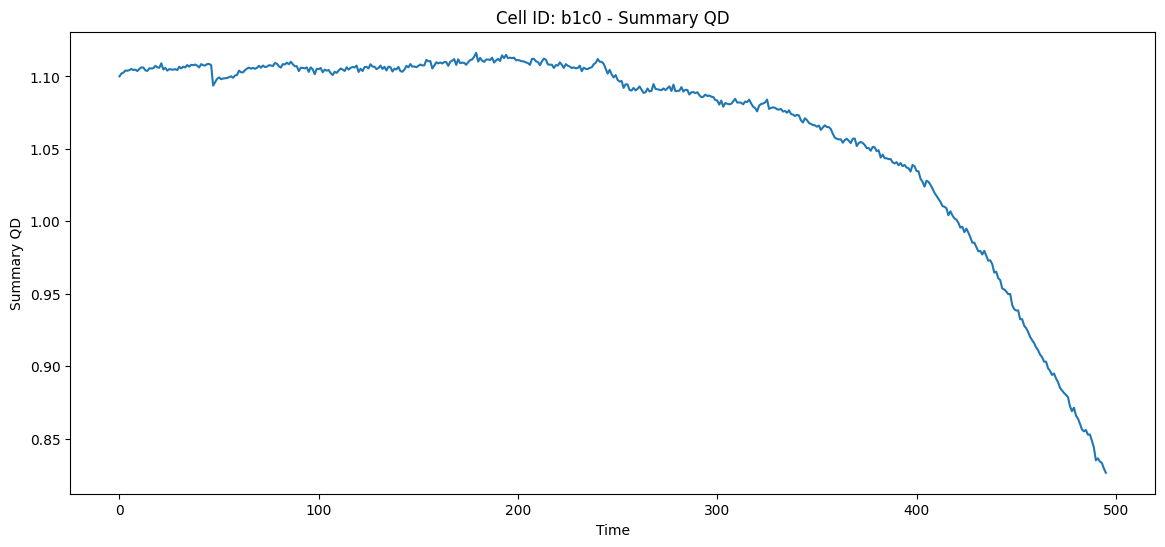

In [ ]:
import matplotlib.pyplot as plt

cell_id = 'b1c0'
cell_data = bat_dict[cell_id]

plt.figure(figsize=(14, 6))
plt.plot(cell_data['summary']['QD'])
plt.title(f'Cell ID: {cell_id} - Summary QD')
plt.xlabel('Time')
plt.ylabel('Summary QD')
plt.show()

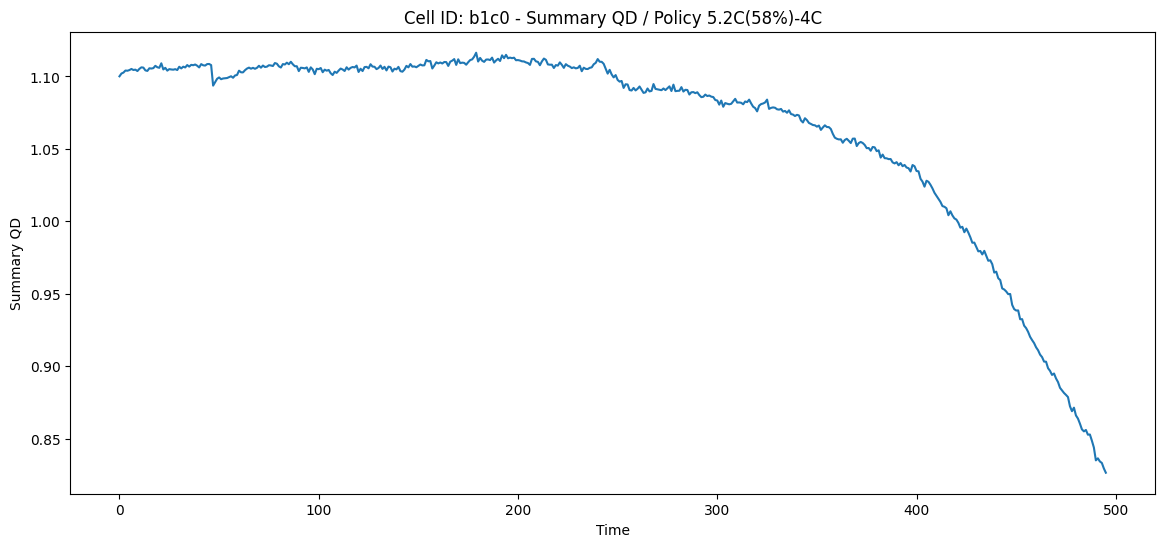

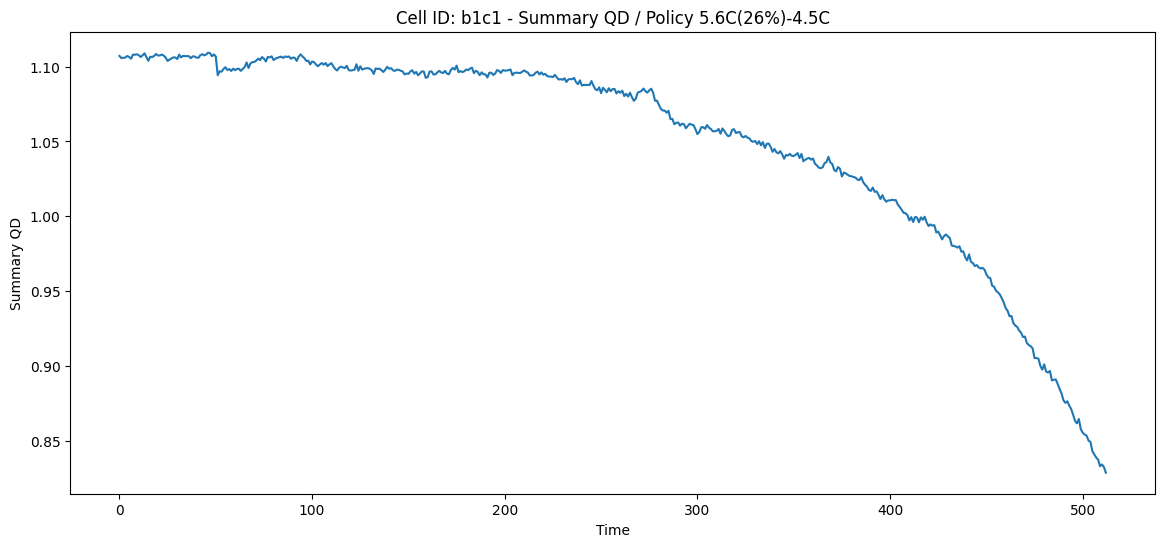

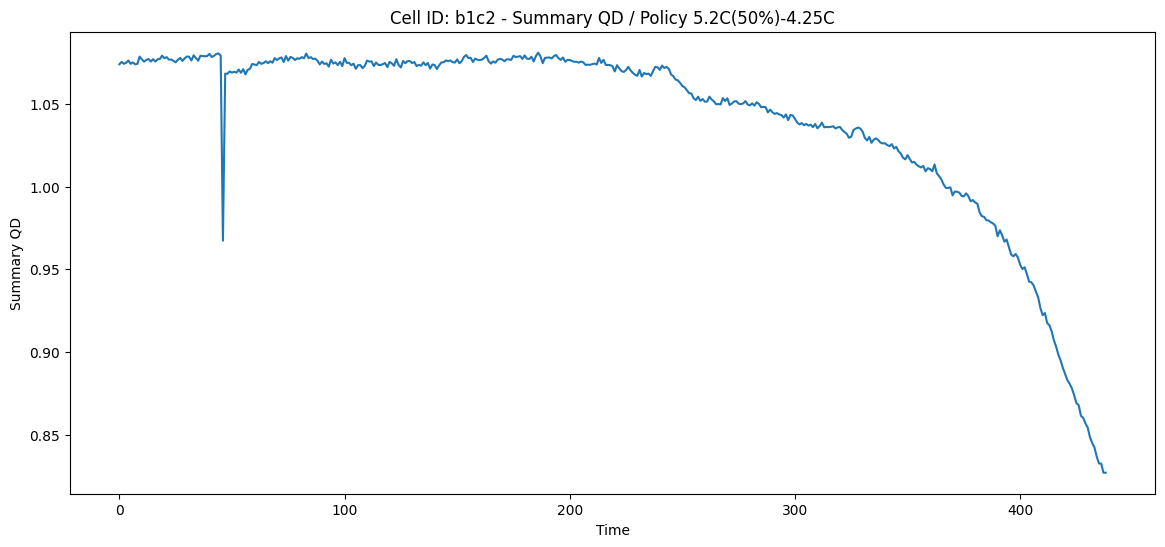

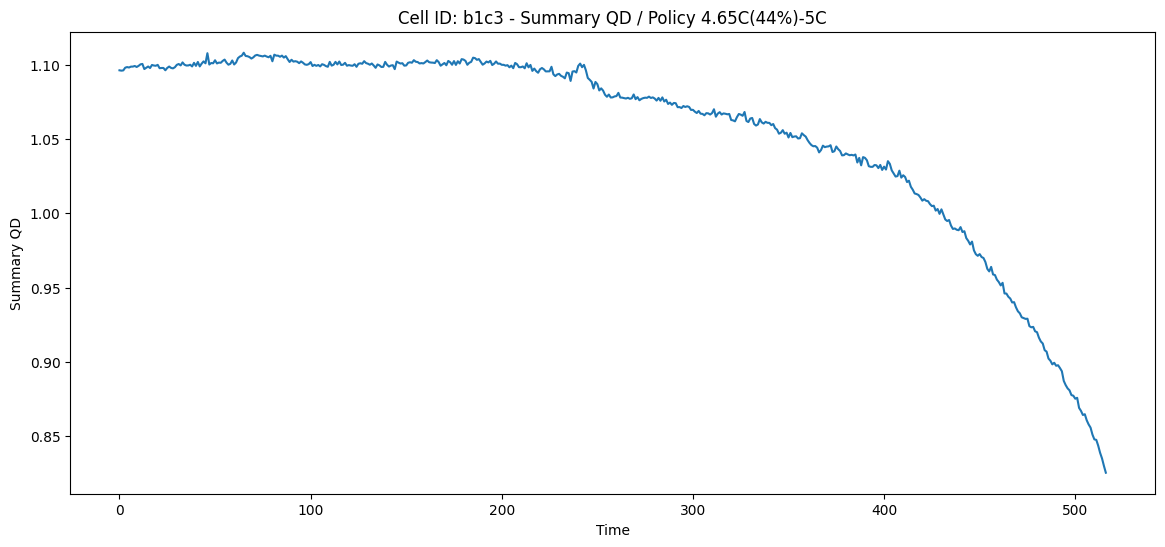

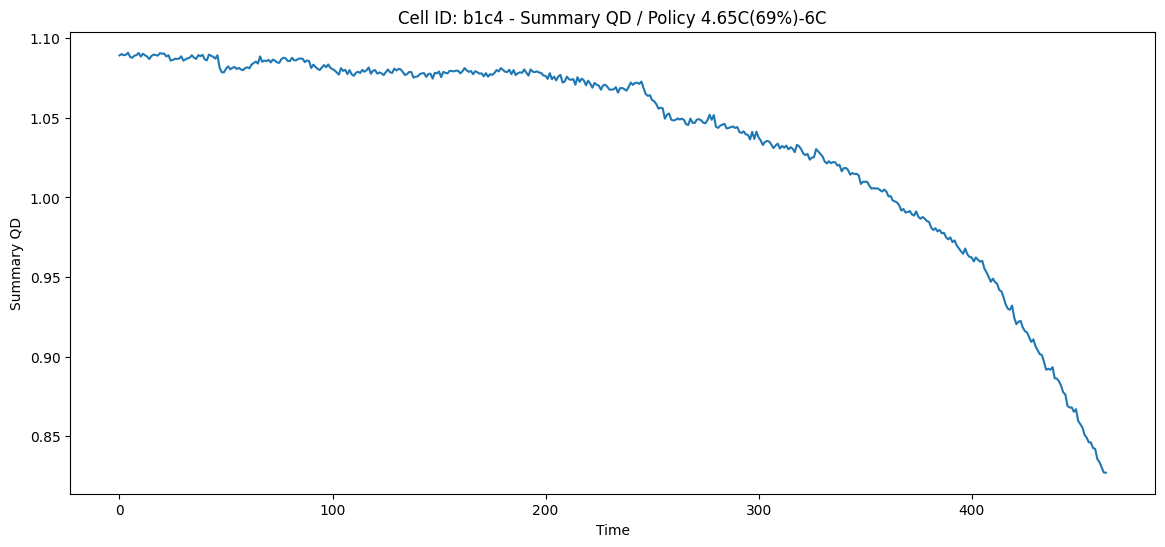

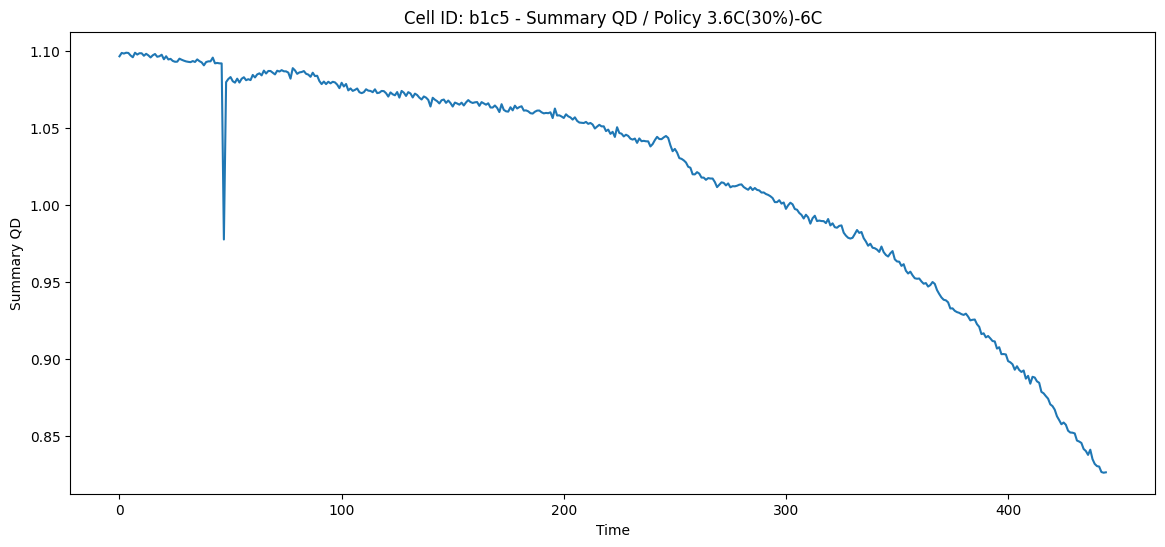

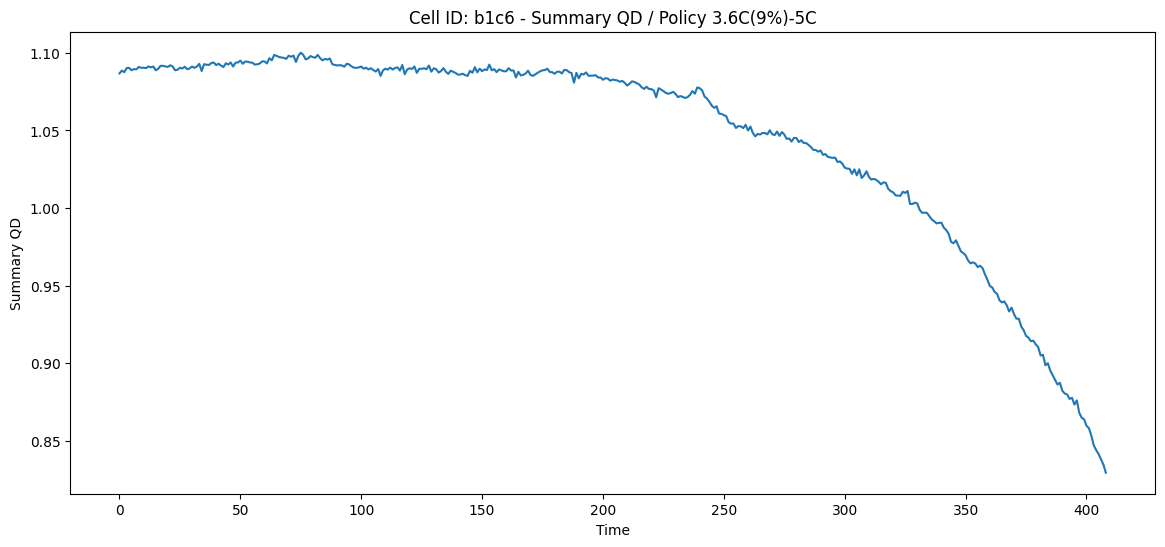

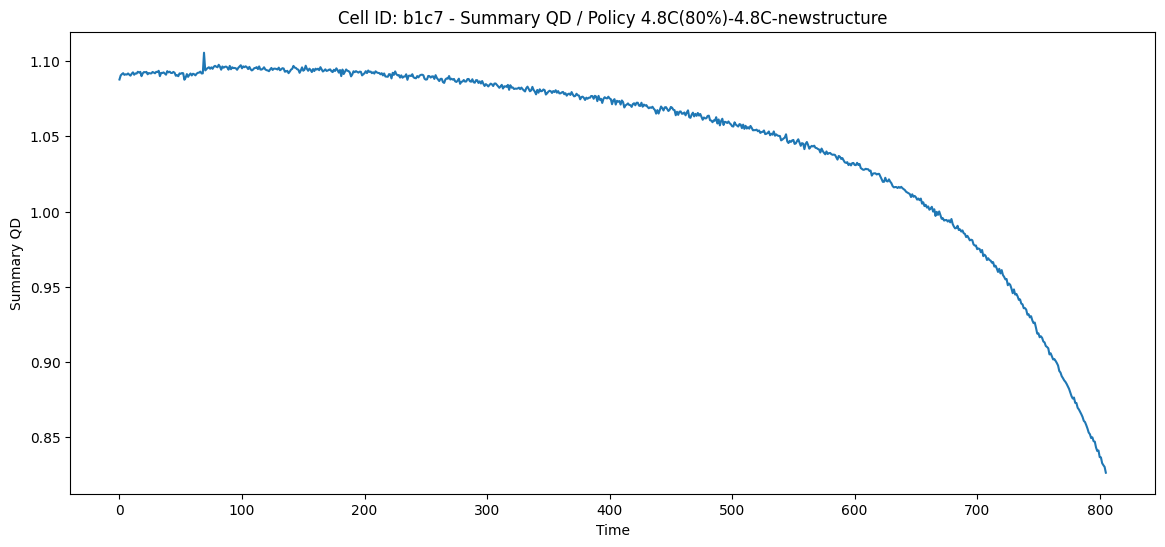

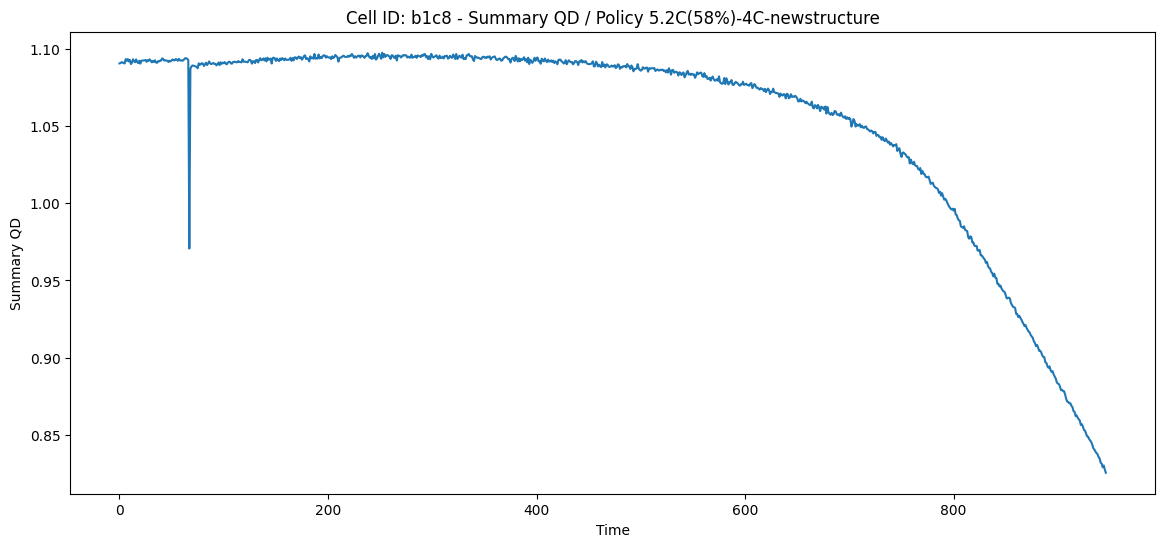

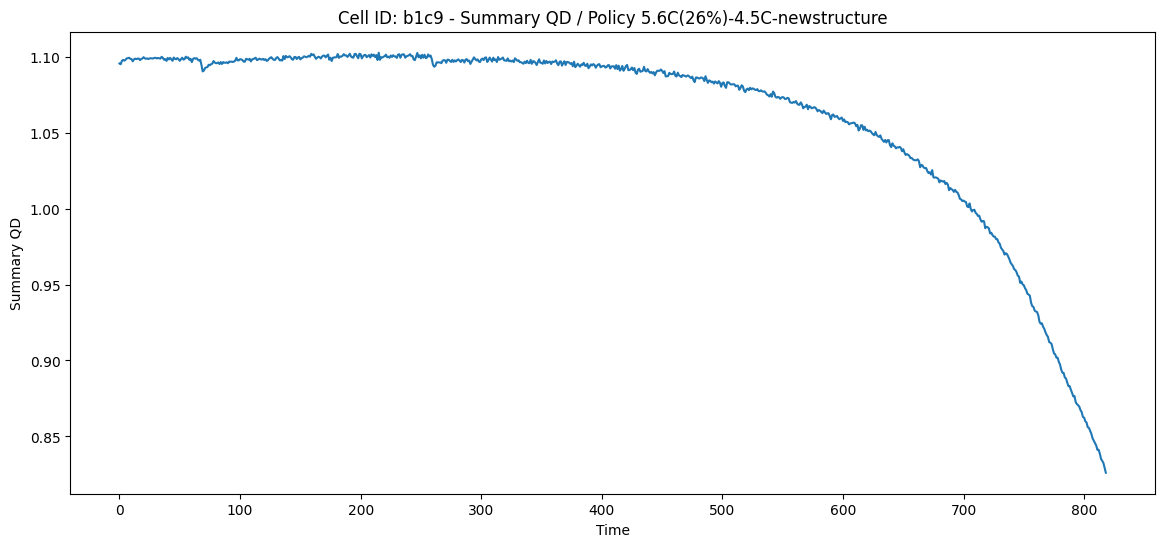

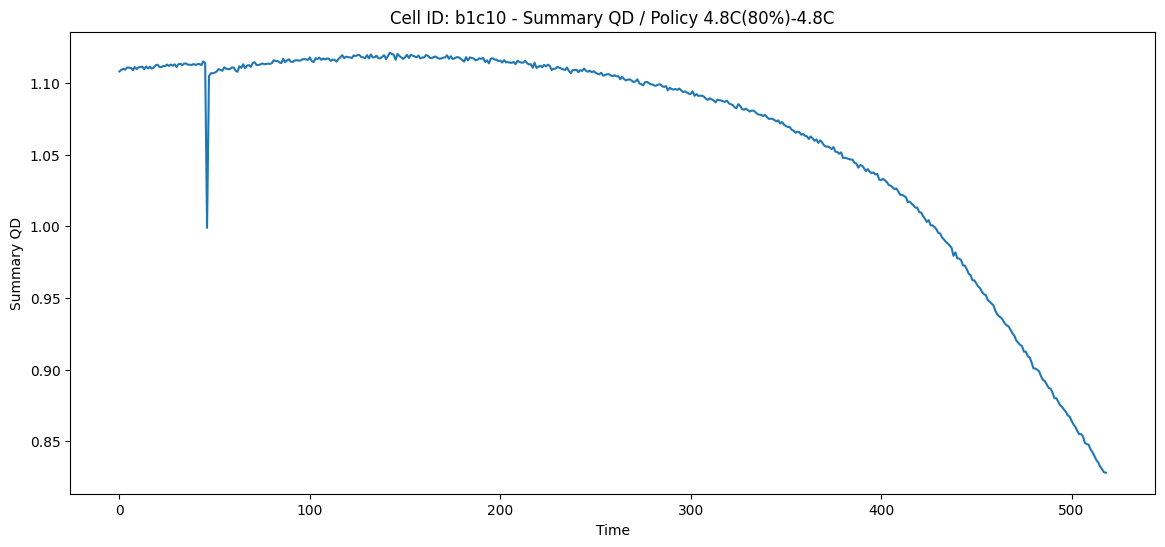

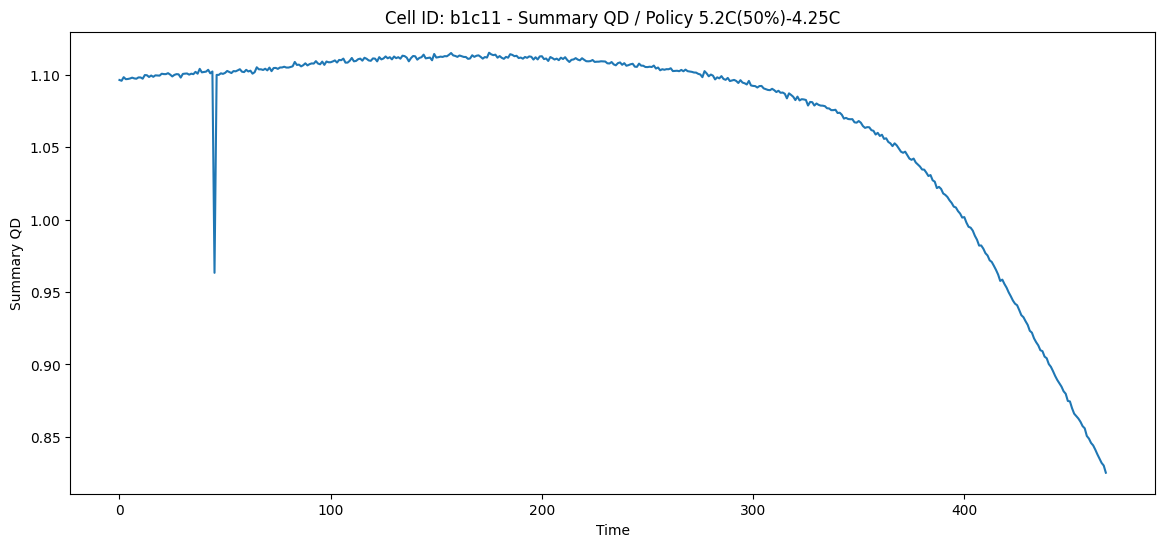

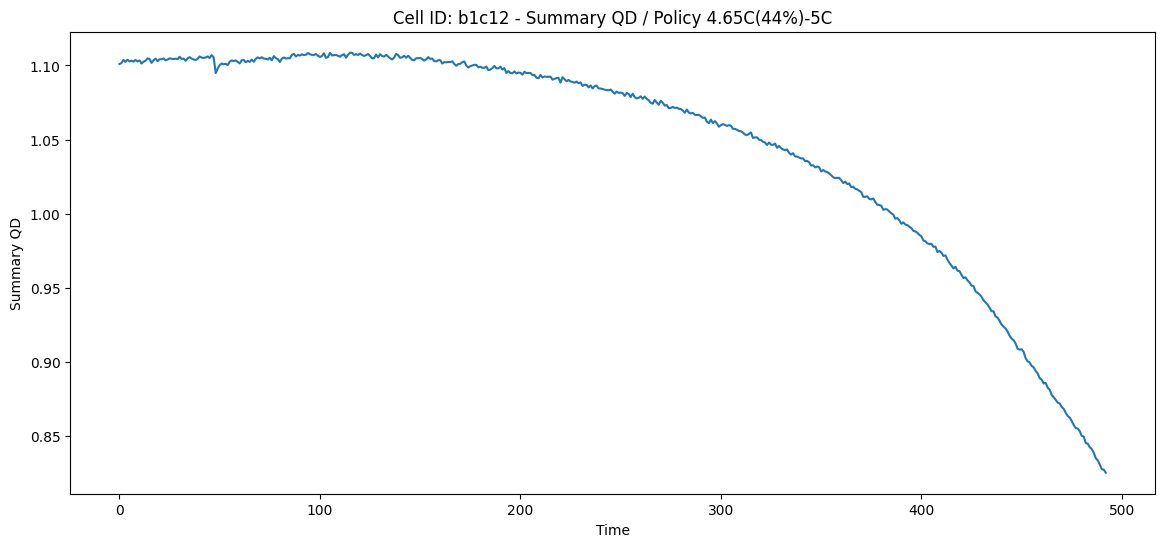

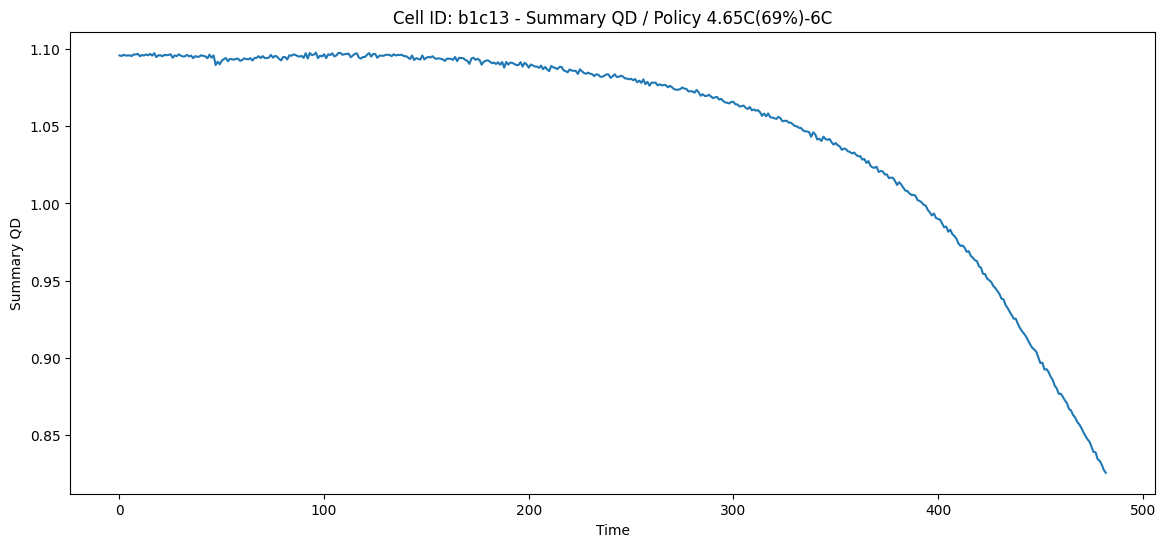

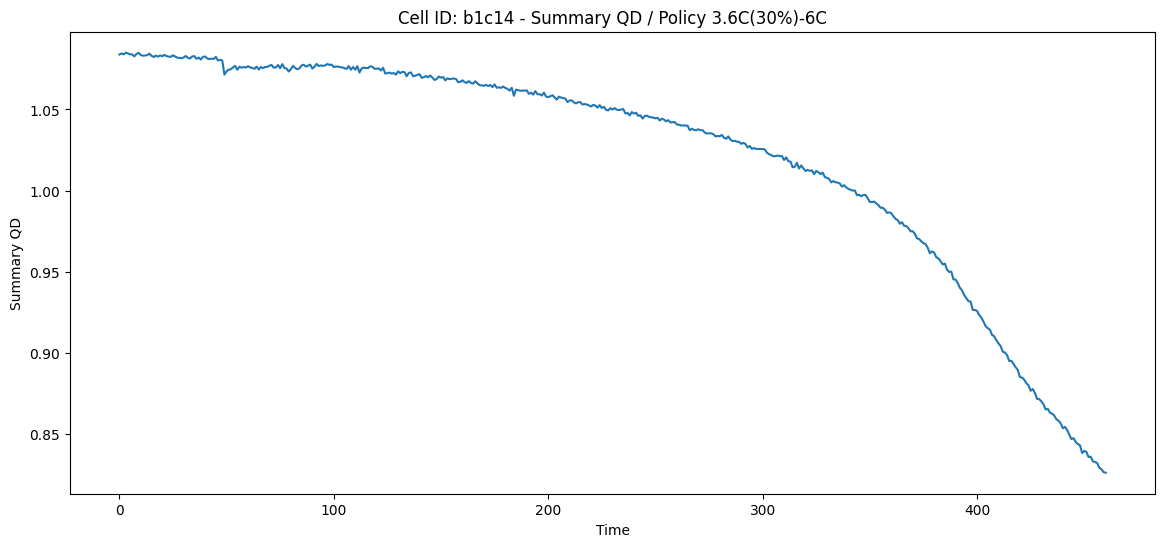

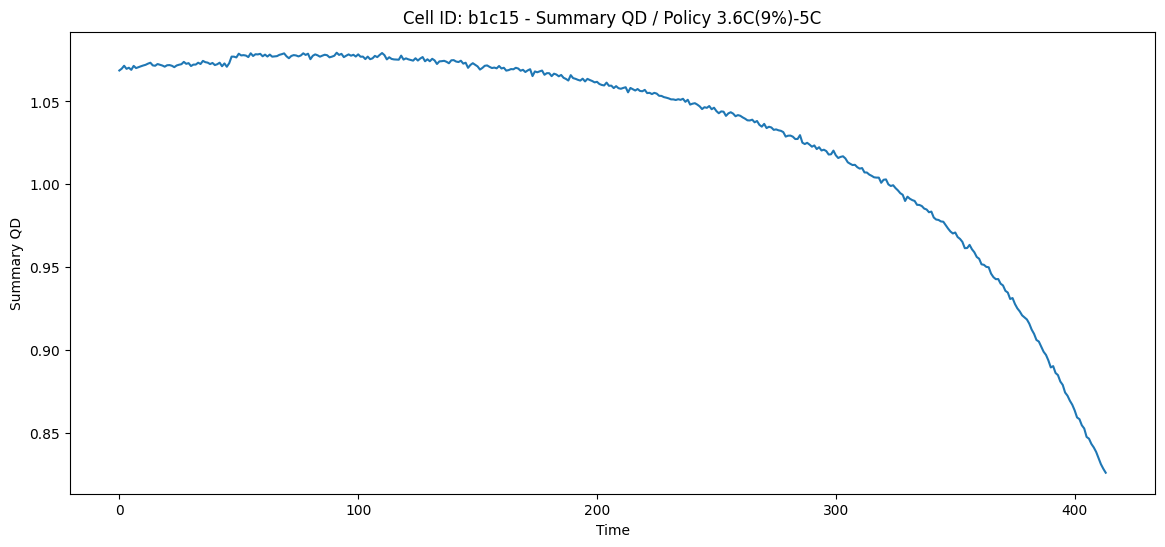

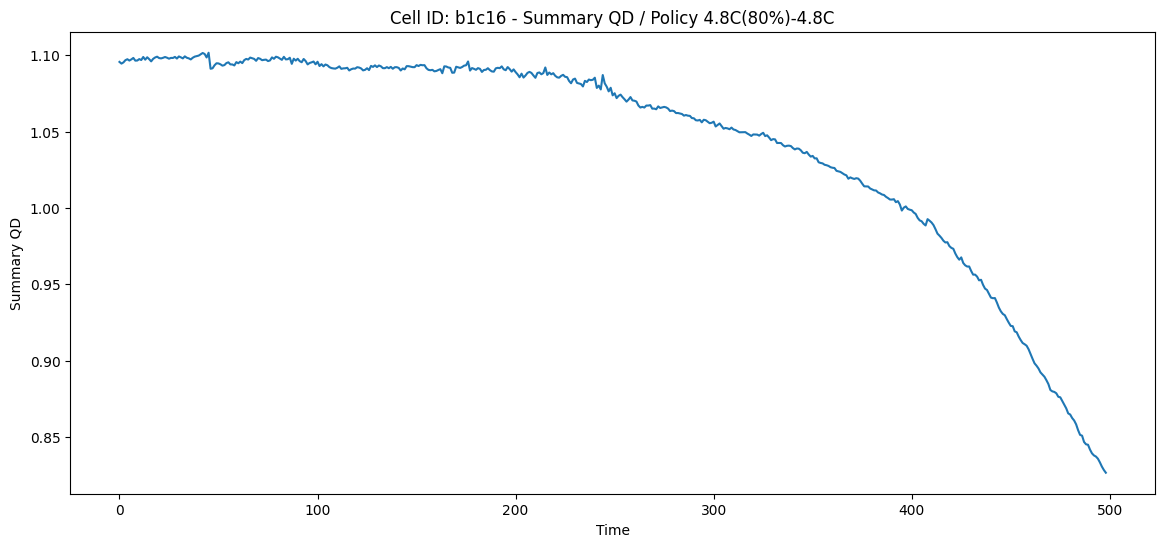

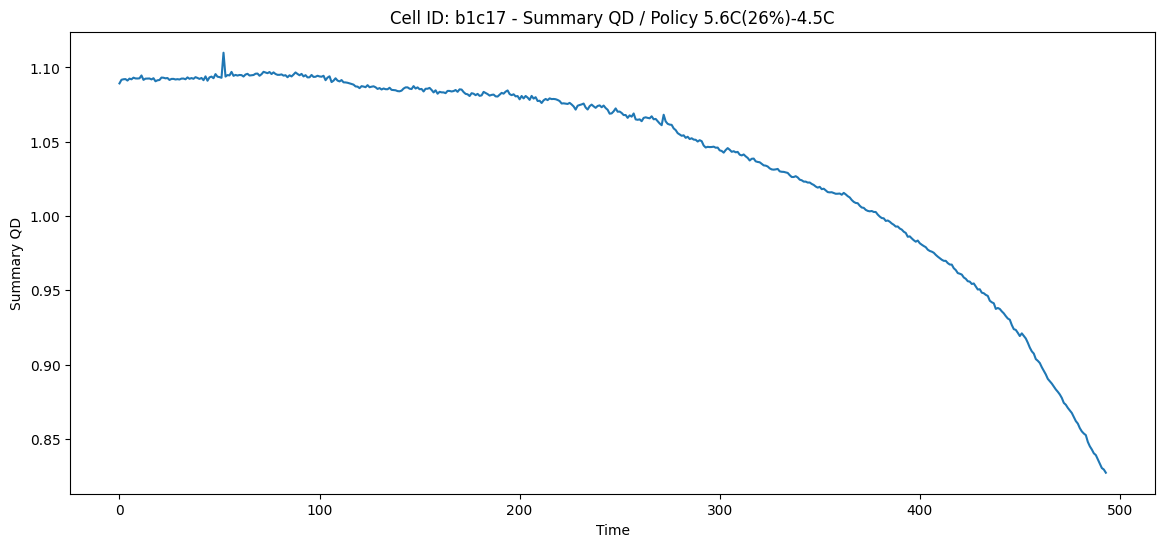

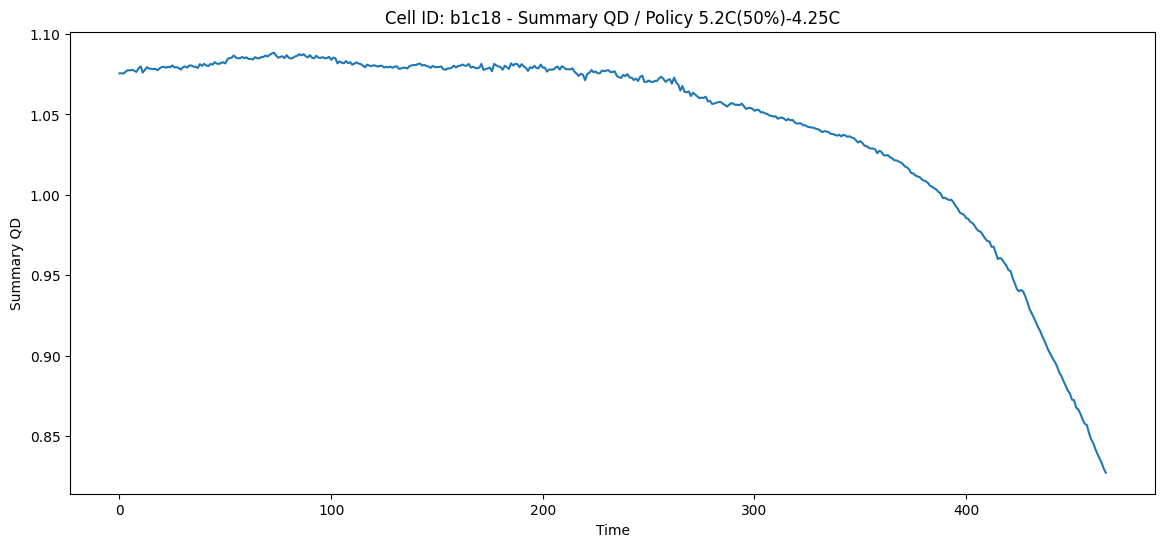

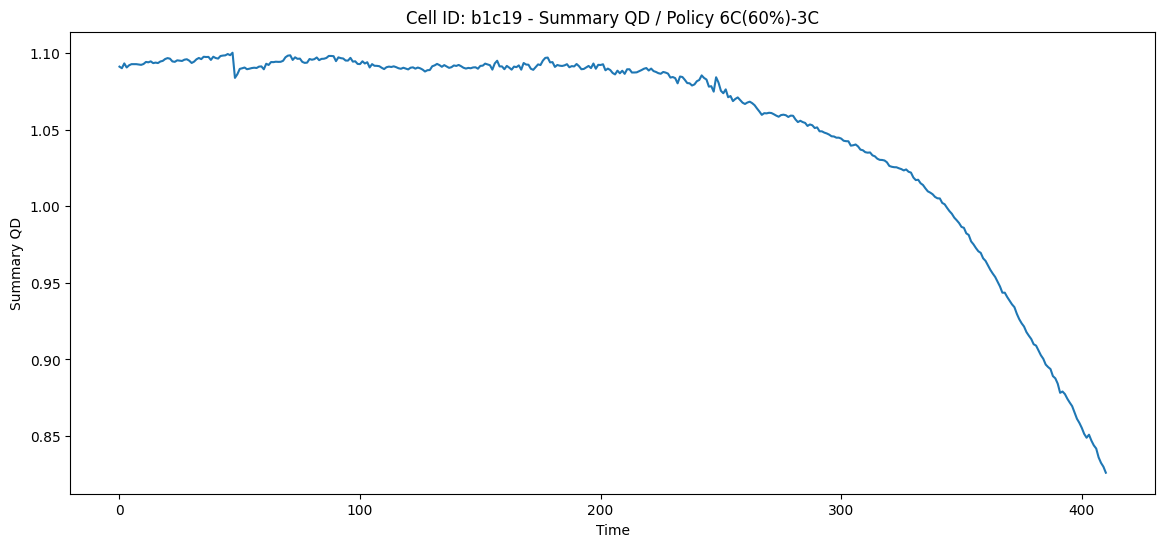

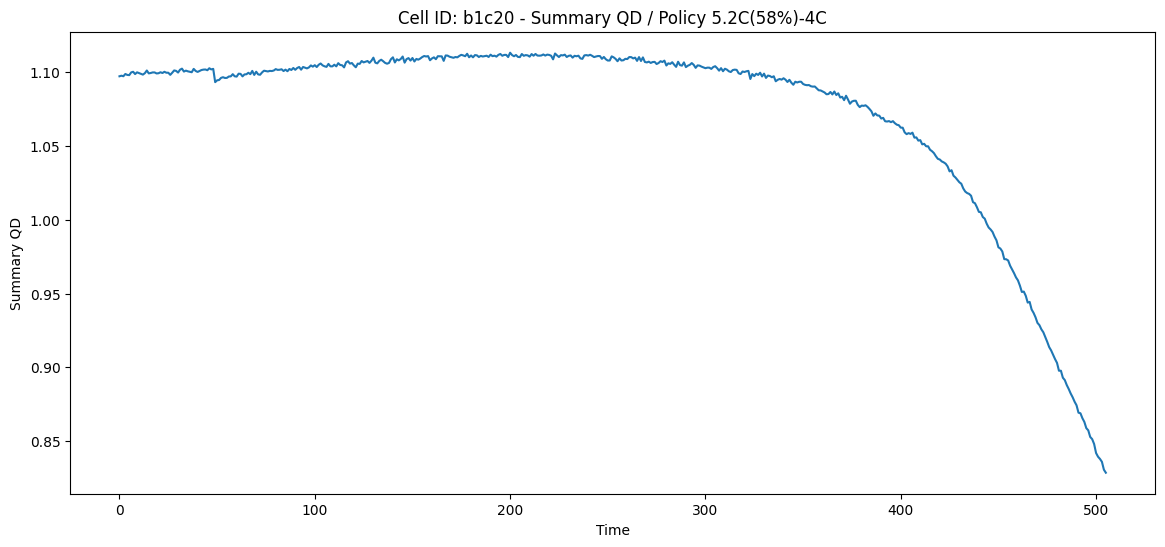

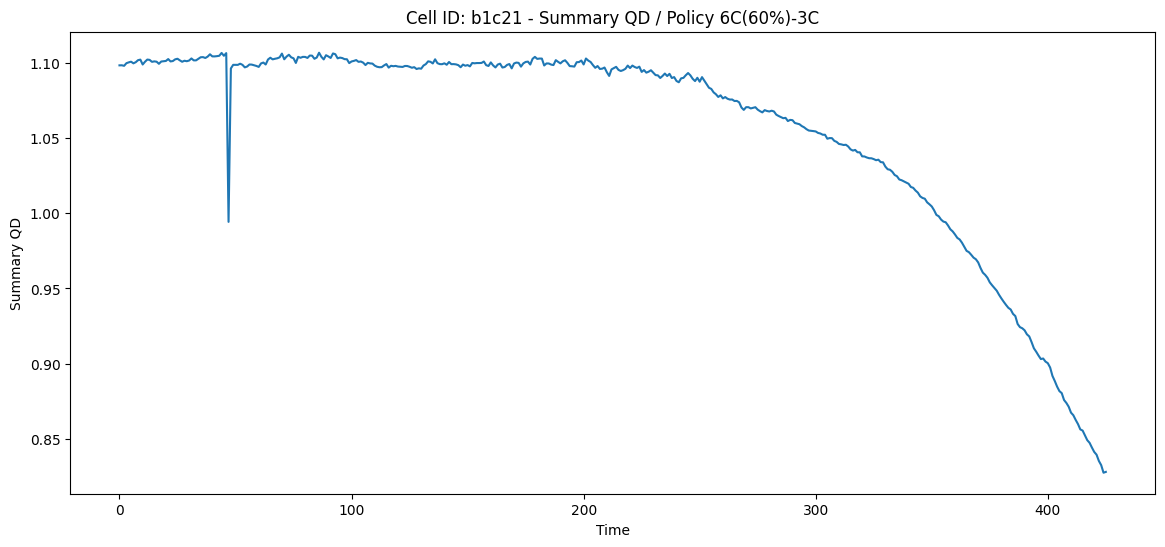

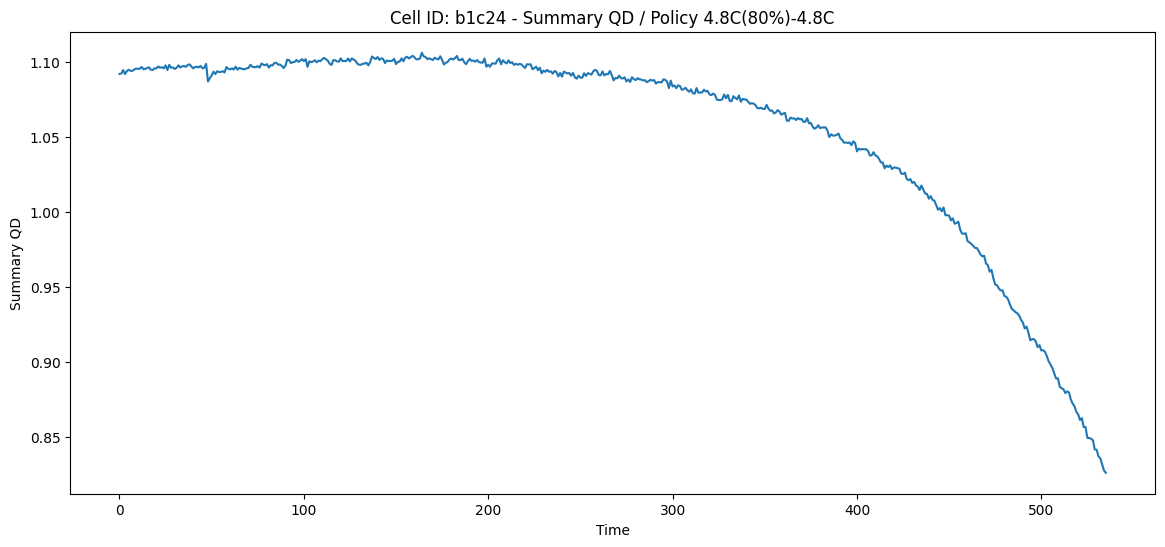

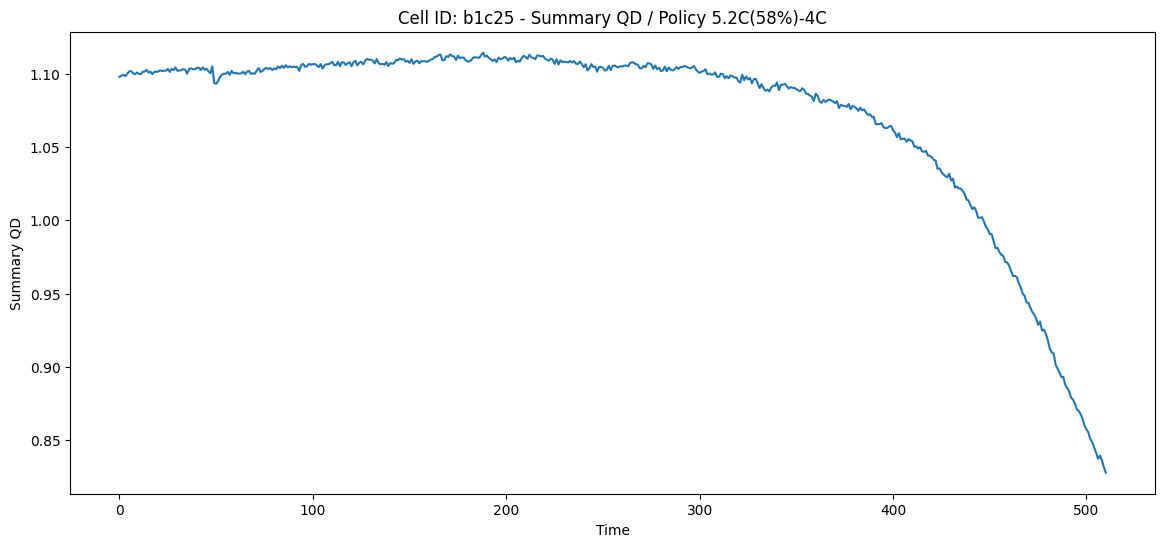

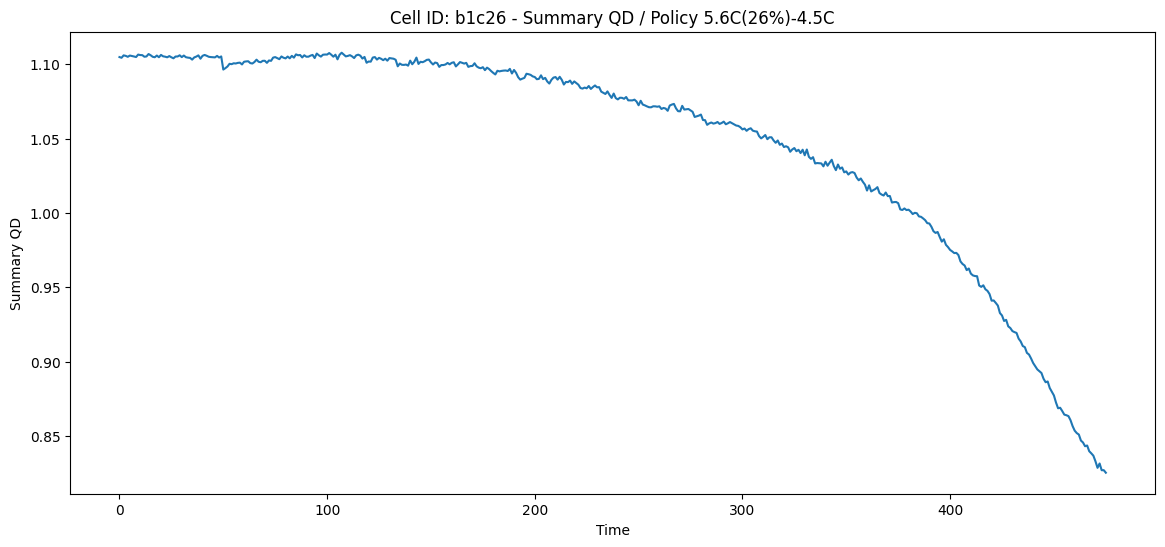

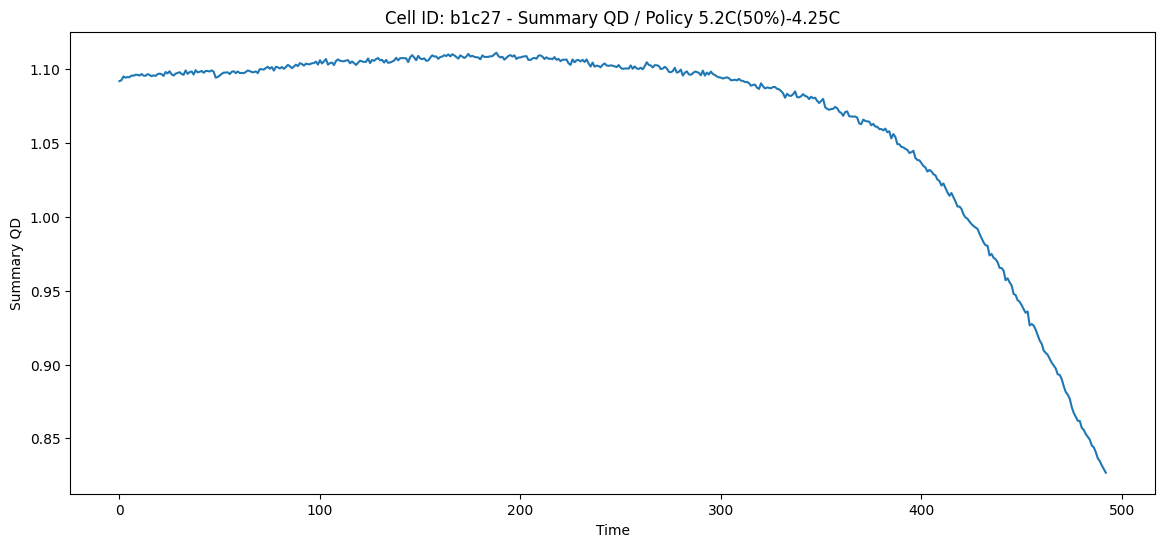

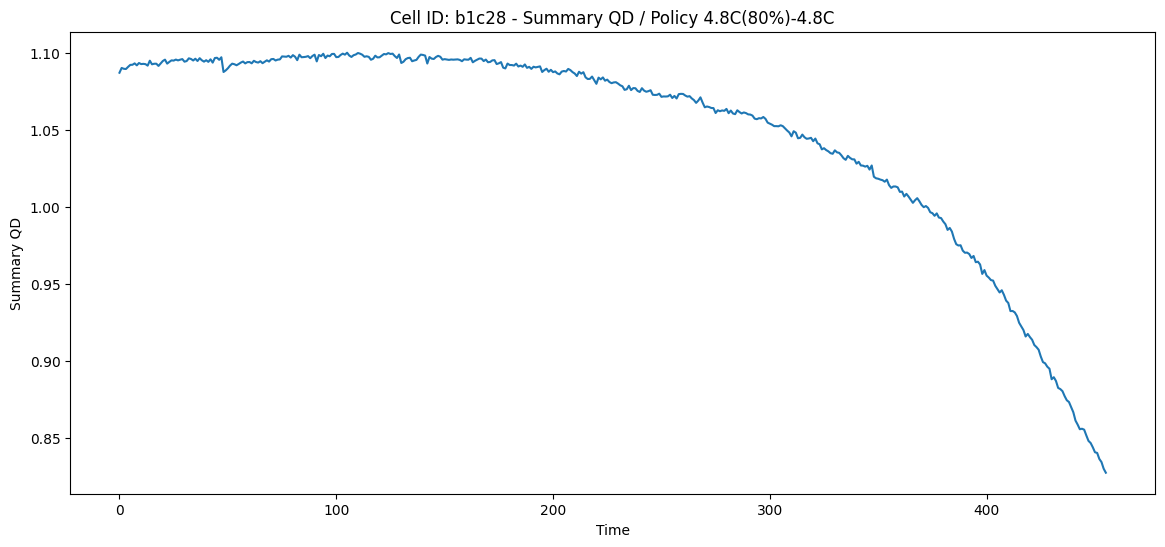

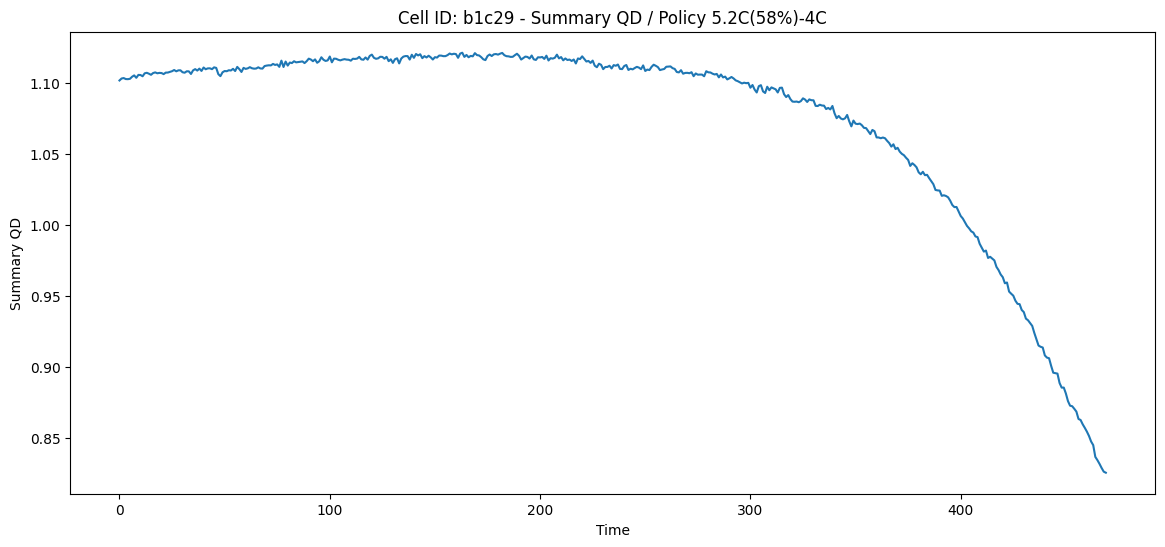

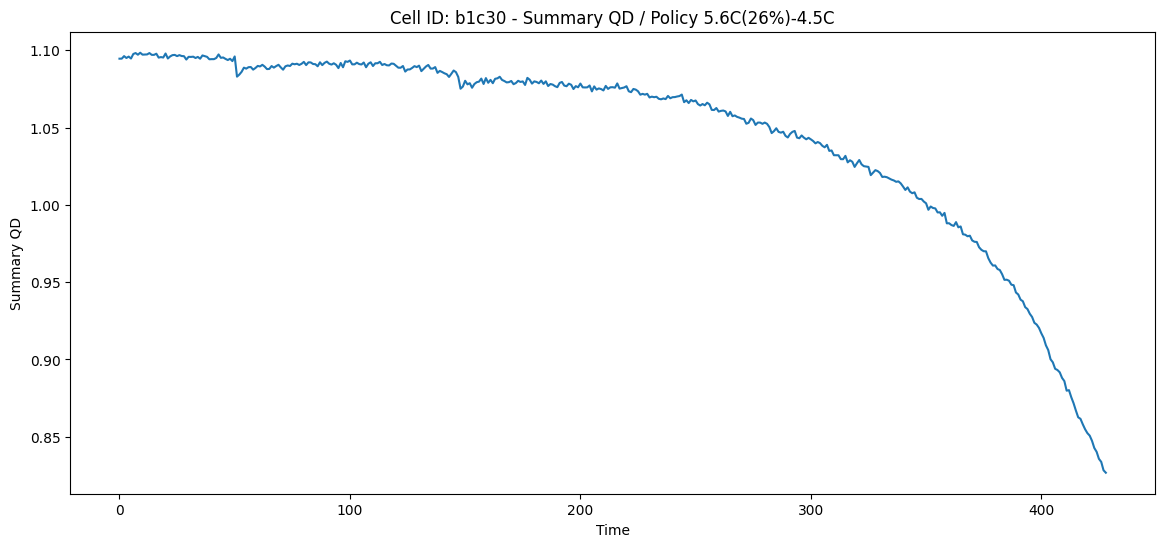

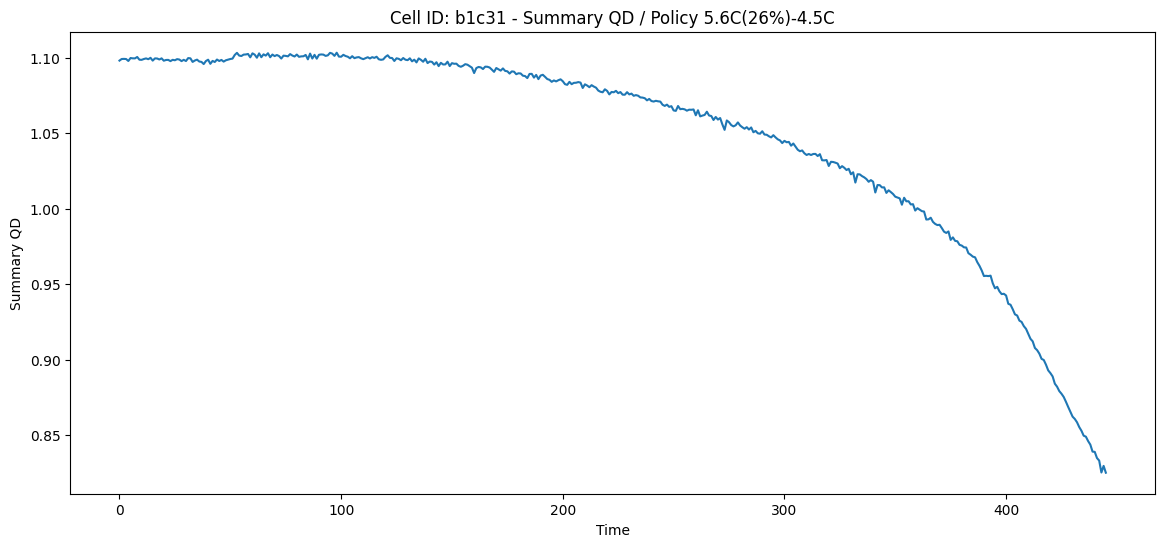

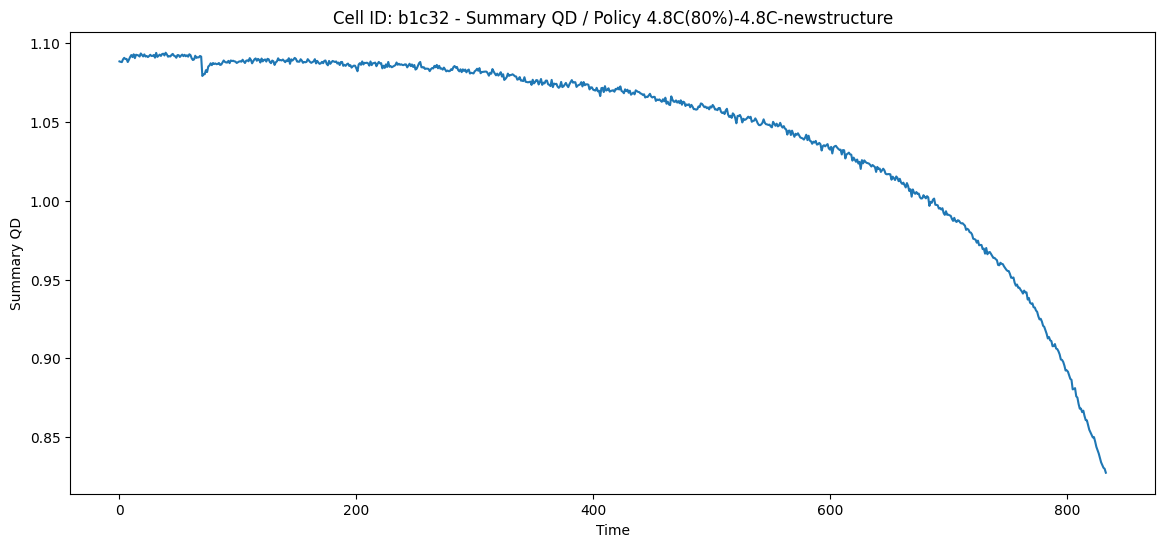

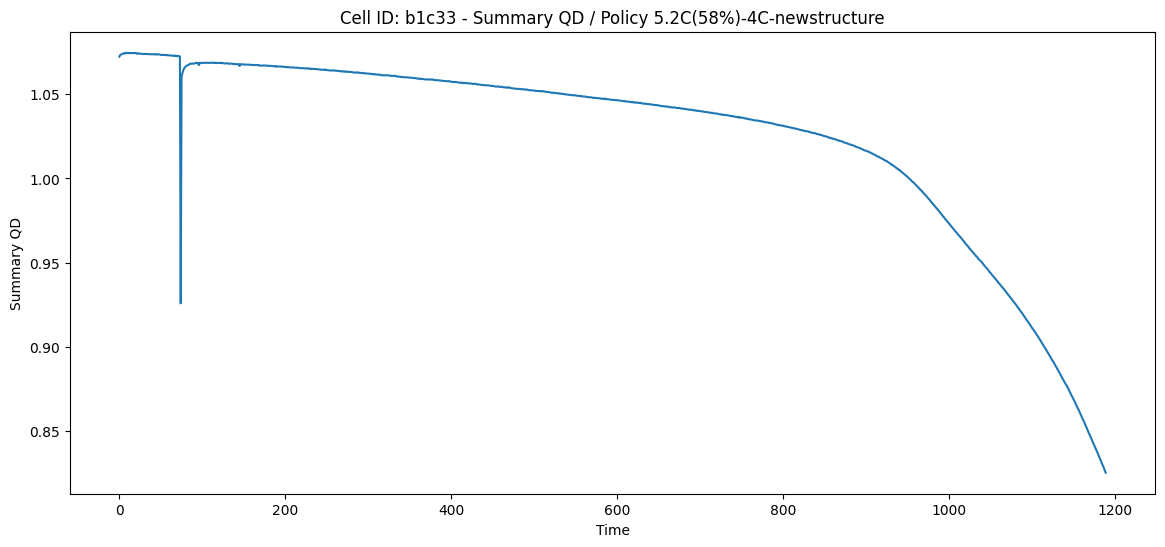

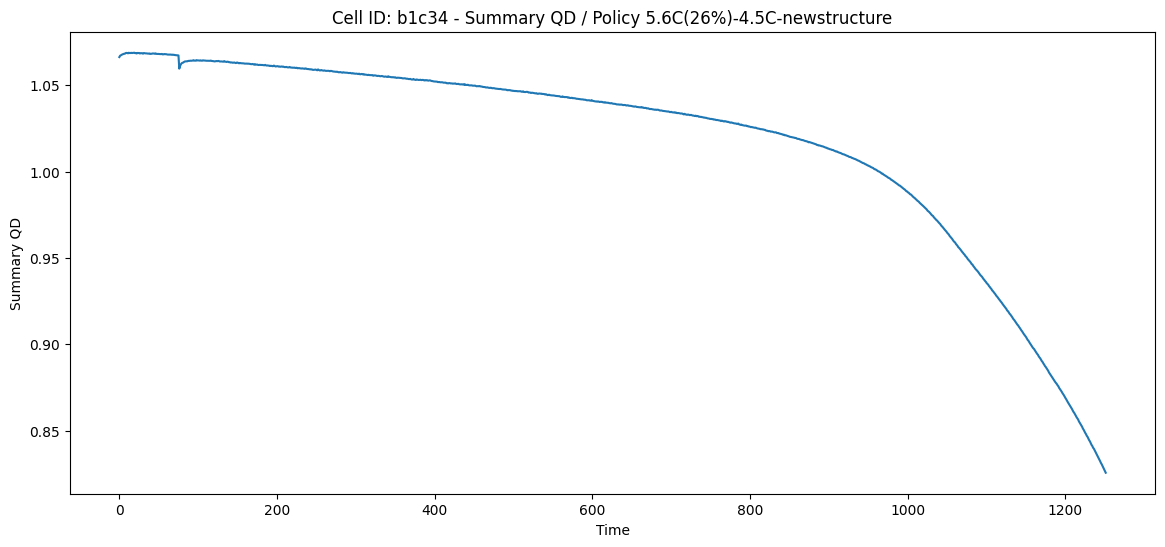

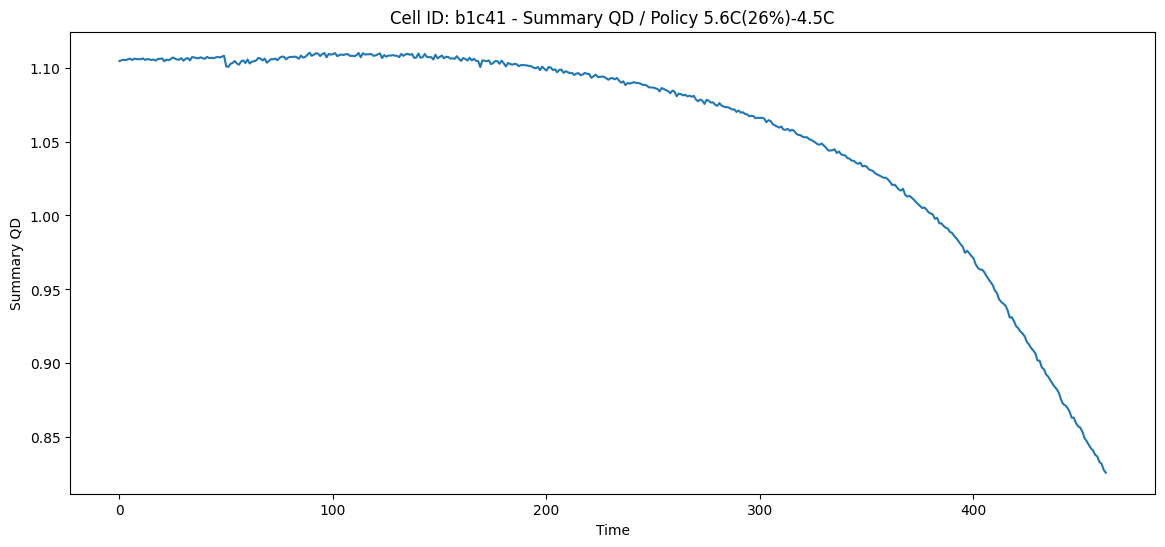

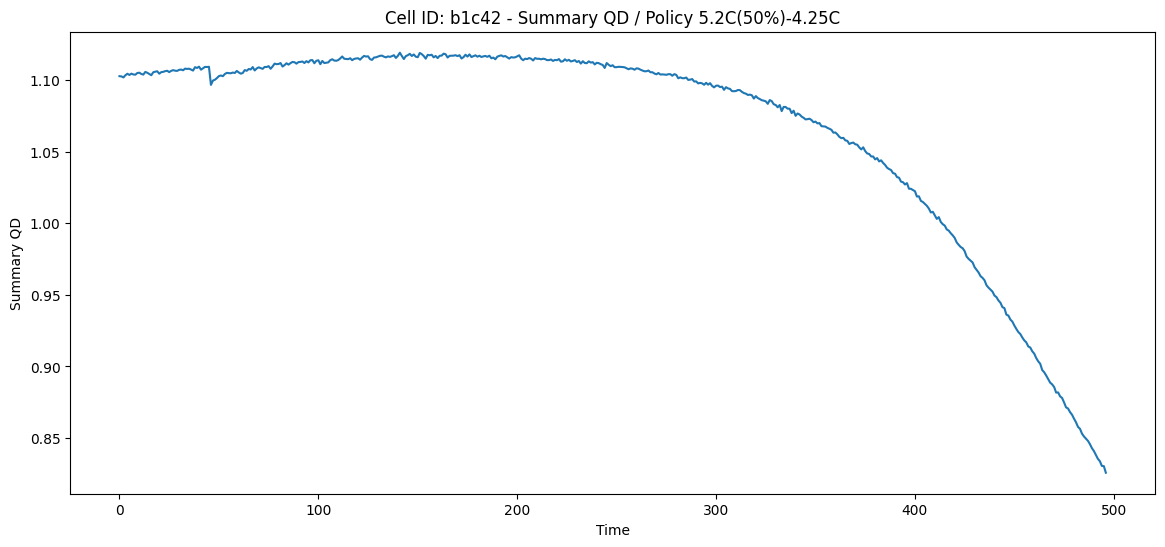

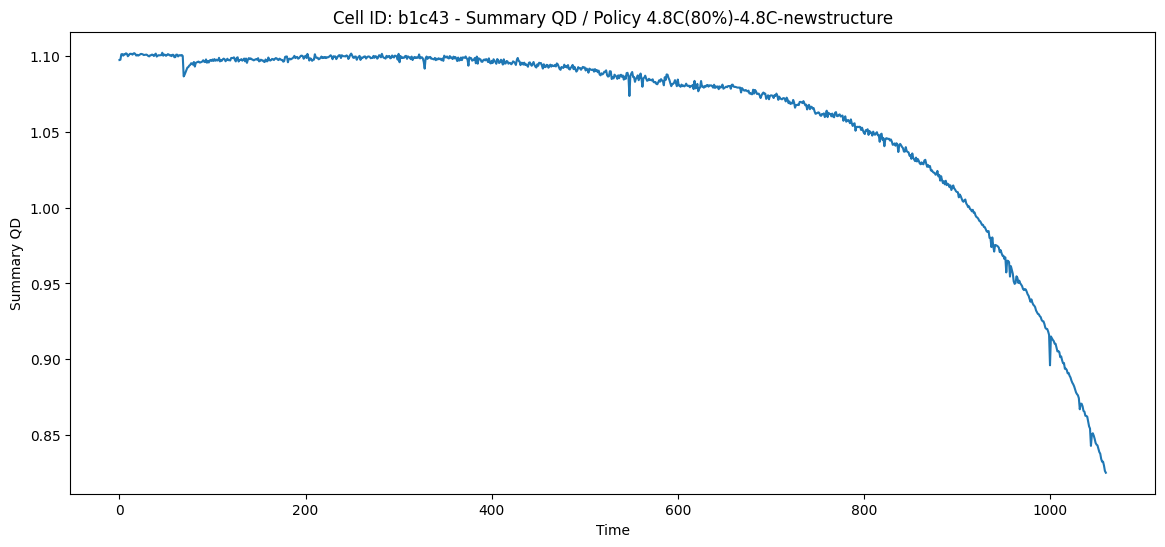

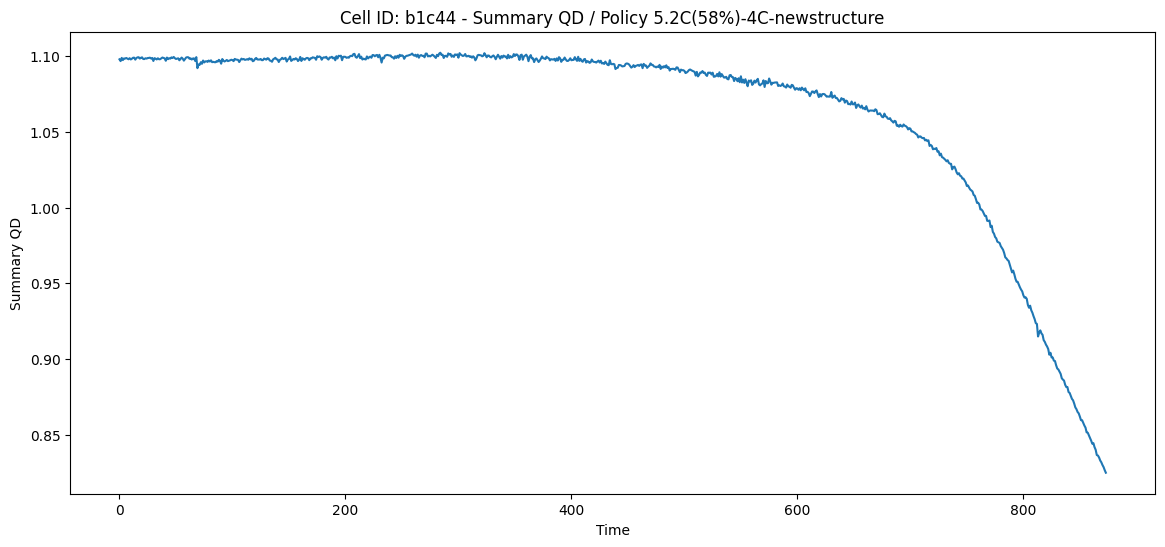

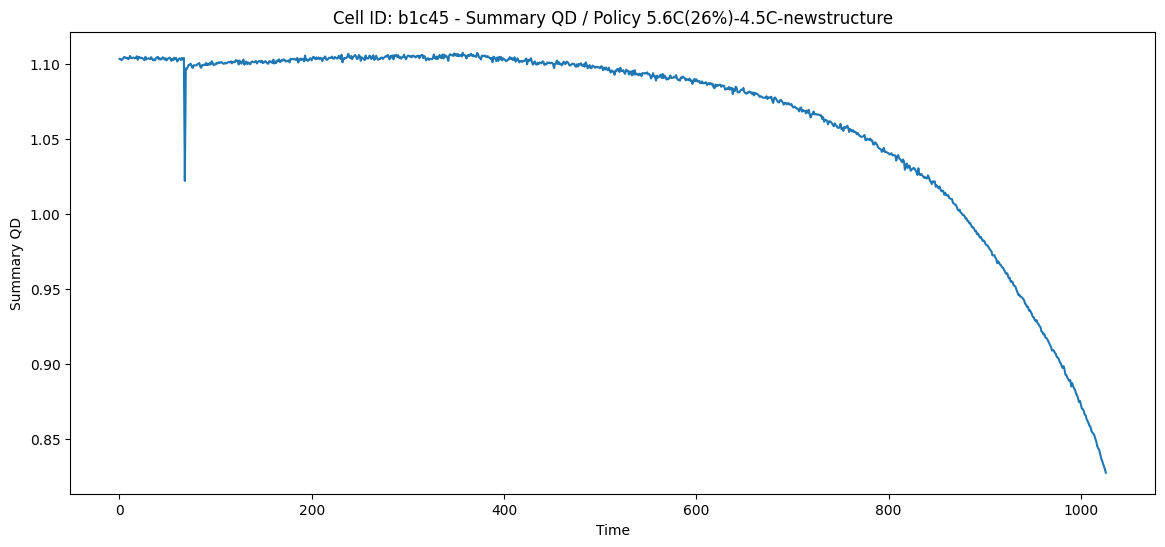

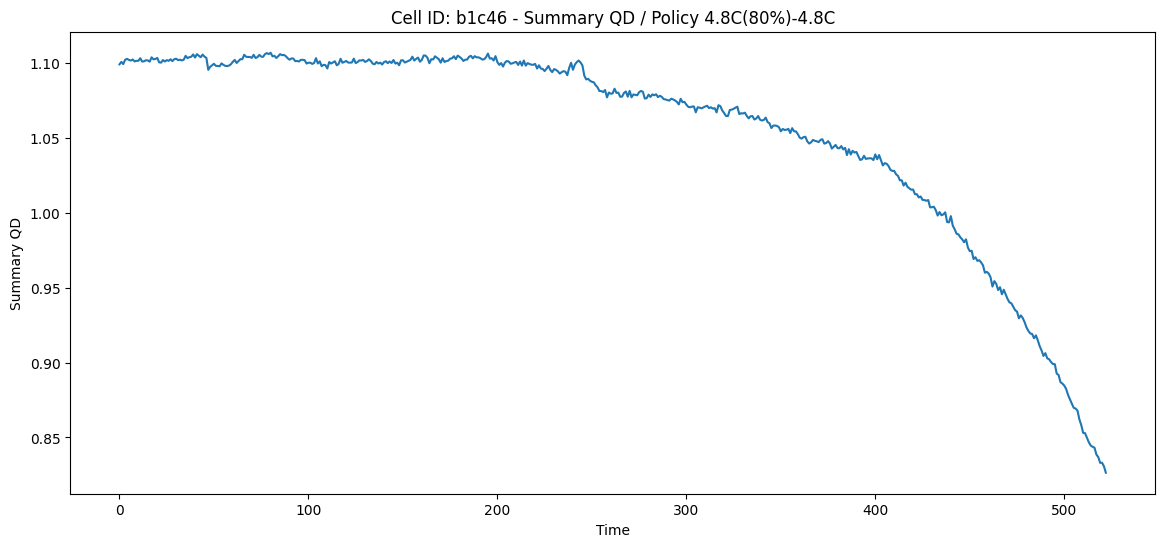

In [14]:
for cell_id, cell_data in bat_dict.items():
    plt.figure(figsize=(14, 6))
    plt.plot(cell_data['summary']['QD'])
    plt.title(f'Cell ID: {cell_id} - Summary QD / Policy {cell_data['charge_policy']}')
    plt.xlabel('Time')
    plt.ylabel('Summary QD')
    plt.show()